# Task 1: Introduction, History, Pipelines & Tokenizer

**Objective:** Use a pretrained Transformer through the Hugging Face pipeline and see how text becomes tokens.

**Expected output:** pipeline predictions, tokenizer output, a padded batch and the model configuration table.

## 1.1 Install and First Pipeline

In [2]:
import os, re, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
warnings.filterwarnings("ignore")

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

os.makedirs("plots", exist_ok=True)

from transformers import pipeline

SENT_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"

clf = pipeline("sentiment-analysis", model=SENT_MODEL)

sentences = [
    "I absolutely loved this movie, the acting was brilliant!",          # positive
    "This was the worst film I have ever seen.",                         # negative
    "The plot was boring and the ending made no sense.",                 # negative
    "What a wonderful and touching story.",                              # positive
    "This movie is not bad at all.",                                     # tricky (negation)
]

for s in sentences:
    out = clf(s)[0]
    print(f"{out['label']:9s} | score = {out['score']:.4f} | {s}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

POSITIVE  | score = 0.9999 | I absolutely loved this movie, the acting was brilliant!
NEGATIVE  | score = 0.9998 | This was the worst film I have ever seen.
NEGATIVE  | score = 0.9998 | The plot was boring and the ending made no sense.
POSITIVE  | score = 0.9999 | What a wonderful and touching story.
POSITIVE  | score = 0.9994 | This movie is not bad at all.


- The pipeline classified all 5 sentences and gave a **label** (POSITIVE / NEGATIVE) and a **score** (confidence between 0 and 1).
- Clear positive and negative sentences get a score very close to **1.0**.
- The tricky sentence with a **negation** ("not bad at all") is the hardest one. Check whether the model got it right and how confident it was.
- **No training was done**: the model was already fine-tuned on the SST-2 dataset.

### What Does One Pipeline Call Hide?

One line `clf(text)` hides **three steps**:

- **Tokenisation:** the text is converted into token IDs.
- **Model forward pass:** the Transformer converts the IDs into logits (raw scores).
- **Post-processing:** softmax turns the logits into probabilities and the biggest one becomes the label.

## 1.2 Introduction and History

## Timeline of Transformers

| Year | Model / Paper | Why it mattered |
|------|---------------|-----------------|
| **2014-15** | Sequence-to-sequence with attention (Bahdanau, Luong) | The decoder could look back at all encoder states instead of one fixed vector |
| **2017** | *Attention Is All You Need* (Vaswani et al.) | Removed the RNN completely and used only attention, so training became parallel |
| **2018** | BERT and GPT | Pretraining on huge text, then fine-tuning for each task (encoder-only and decoder-only) |
| **2019** | GPT-2, T5, DistilBERT | Bigger generators, the text-to-text idea (T5) and smaller, faster models (DistilBERT) |
| **2020 and later** | GPT-3, Vision Transformer (ViT), large language models | Transformers spread to images and became chat assistants |

### What Problem Did the Transformer Solve?

- RNNs and LSTMs (Module 9) read the words **one by one**, so training could not run in parallel and was **slow**.
- They also had a **short memory**: the information from early words fades (vanishing gradient).
- The Transformer lets **every token look at every other token directly** in one step, so it is **parallel** and can connect words that are far apart.

## 1.3 Impact and Disadvantages

## Impact

- **Machine translation** and text summarisation
- **Search engines** that understand the meaning of a query
- **Chat assistants** and question answering
- **Code completion** tools
- **Image models** (Vision Transformers)
- **Protein structure prediction**

## Disadvantages

- **Quadratic attention cost:** every token is compared with every other token, so the cost grows with the square of the length *(measured in Task 6.3)*.
- **Fixed context window:** a model can only read a limited number of tokens, for example 512 *(measured in Task 6.2)*.
- **Large compute and memory needs**
- **Need for huge amounts of data**
- **Hallucination:** generative models can write fluent but false facts *(checked in Task 6.4)*.
- **Opaque behaviour:** it is hard to explain exactly why the model gave an answer.

## 1.4 Tokenizer in Action

In [3]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(SENT_MODEL)

text = "Transformers are surprisingly easy to understand."

print("Tokens        :", tok.tokenize(text))

enc = tok(text)
print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])

print("\nTokens with special tokens:", tok.convert_ids_to_tokens(enc["input_ids"]))

Tokens        : ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
input_ids     : [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]

Tokens with special tokens: ['[CLS]', 'transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.', '[SEP]']


In [4]:
# A rare and long word is split into sub-word pieces
rare_text = "Electroencephalography is unbelievably complicated."

print("Tokens:", tok.tokenize(rare_text))

Tokens: ['electro', '##ence', '##pha', '##log', '##raphy', 'is', 'un', '##bel', '##ie', '##va', '##bly', 'complicated', '.']


- The text was converted into **lower-case tokens**, and each token has an integer **ID**.
- The IDs start with **[CLS]** (101) and end with **[SEP]** (102), which were added automatically.
- The **attention_mask** is all 1s because every token is a real token.
- The rare long word was split into **sub-word pieces**. The pieces that start with `##` continue the previous piece.

### What Do [CLS] and [SEP] Do, and Why Sub-Words?

- **[CLS]** is put at the start. Its final vector is used as a summary of the whole sentence for classification.
- **[SEP]** marks the end of a sentence (or the border between two sentences).
- **Sub-words** are used instead of whole words so that the vocabulary stays small (about 30,000 pieces) and **any new or rare word** can still be built from known pieces. There are no unknown words.

## 1.5 Batching and Padding

In [5]:
batch = tok(
    ["I loved it.", "The movie was long, slow and honestly a little bit boring."],
    padding=True,
    return_tensors="pt"
)

print("input_ids:\n", batch["input_ids"])
print("\nattention_mask:\n", batch["attention_mask"])

input_ids:
 tensor([[  101,  1045,  3866,  2009,  1012,   102,     0,     0,     0,     0,
             0,     0,     0,     0,     0],
        [  101,  1996,  3185,  2001,  2146,  1010,  4030,  1998,  9826,  1037,
          2210,  2978, 11771,  1012,   102]])

attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


- The shorter sentence was filled with **0 (the [PAD] token)** so that both rows have the same length.
- The **attention_mask** has **1 for real tokens** and **0 for padding**.
- This mask tells the model to **ignore the padding**. We will see its effect in Task 4.8.

## 1.6 Model Anatomy at a Glance

In [6]:
from transformers import AutoModelForSequenceClassification

# eager attention is needed later to get the attention weights
model = AutoModelForSequenceClassification.from_pretrained(SENT_MODEL, attn_implementation="eager")
model.eval()

print(model.config)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForSequenceClassification"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "finetuning_task": "sst-2",
  "hidden_dim": 3072,
  "id2label": {
    "0": "NEGATIVE",
    "1": "POSITIVE"
  },
  "initializer_range": 0.02,
  "label2id": {
    "NEGATIVE": 0,
    "POSITIVE": 1
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "output_past": true,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.1",
  "vocab_size": 30522
}



In [7]:
total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", total_params)

print("\nFirst 15 parameter names:")
for i, (name, p) in enumerate(model.named_parameters()):
    if i == 15:
        break
    print(f"{name:65s} {tuple(p.shape)}")

Total parameters: 66955010

First 15 parameter names:
distilbert.embeddings.word_embeddings.weight                      (30522, 768)
distilbert.embeddings.position_embeddings.weight                  (512, 768)
distilbert.embeddings.LayerNorm.weight                            (768,)
distilbert.embeddings.LayerNorm.bias                              (768,)
distilbert.transformer.layer.0.attention.q_lin.weight             (768, 768)
distilbert.transformer.layer.0.attention.q_lin.bias               (768,)
distilbert.transformer.layer.0.attention.k_lin.weight             (768, 768)
distilbert.transformer.layer.0.attention.k_lin.bias               (768,)
distilbert.transformer.layer.0.attention.v_lin.weight             (768, 768)
distilbert.transformer.layer.0.attention.v_lin.bias               (768,)
distilbert.transformer.layer.0.attention.out_lin.weight           (768, 768)
distilbert.transformer.layer.0.attention.out_lin.bias             (768,)
distilbert.transformer.layer.0.sa_layer_norm

In [8]:
cfg = model.config

summary = pd.DataFrame({
    "Item": ["Number of layers", "Attention heads", "Hidden size (d_model)", "Feed-forward size",
             "Vocabulary size", "Max position embeddings", "Total parameters"],
    "Value": [cfg.n_layers, cfg.n_heads, cfg.dim, cfg.hidden_dim,
              cfg.vocab_size, cfg.max_position_embeddings, f"{total_params:,}"]
})

summary

,Item,Value
0,Number of layers,6
1,Attention heads,12
2,Hidden size (d_model),768
3,Feed-forward size,3072
4,Vocabulary size,30522
5,Max position embeddings,512
6,Total parameters,"66,955,010"


- DistilBERT has **6 layers**, **12 attention heads**, a hidden size of **768** and a feed-forward size of **3072**.
- The vocabulary has about **30,522** sub-words and the model can read at most **512 positions**.
- The model has about **67 million parameters**.
- The parameter names show the structure: `embeddings`, then `transformer.layer.N.attention`, `ffn` and the layer norms. We will explain each part in Tasks 2-4.

# Task 2: Self-Attention & Scaled Dot-Product Attention

**Objective:** Build attention from scratch in NumPy and check it against the real model.

**Expected output:** attention heatmap, scaling experiment, Luong attention, order-blind demo and a verification with DistilBERT.

## 2.1 Self-Attention Idea

## What is Self-Attention?

- Every token is turned into **three vectors**:
  - **Query (Q)** = "what am I looking for?"
  - **Key (K)** = "what do I offer?"
  - **Value (V)** = "what information do I pass on?"
- The new vector of a token is a **weighted average of all Value vectors**. The weights come from **how well its Query matches every Key**.
- The whole sequence is processed **in parallel**, unlike an RNN that must go word by word.

$$
\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^{T}}{\sqrt{d_k}}\right)V
$$

## 2.2 Scaled Dot-Product Attention from Scratch

In [9]:
def softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)        # subtract max for stability
    e = np.exp(x)
    return e / np.sum(e, axis=axis, keepdims=True)


def self_attention(X, Wq, Wk, Wv, mask=None):
    Q = X @ Wq
    K = X @ Wk
    V = X @ Wv
    d_k = K.shape[-1]

    scores = Q @ K.T / np.sqrt(d_k)
    if mask is not None:
        scores = scores + mask                          # used later for the causal mask
    weights = softmax(scores, axis=-1)
    output = weights @ V
    return output, weights, (Q, K, V, scores)


rng = np.random.default_rng(42)

X  = rng.standard_normal((4, 8))          # 4 tokens, d_model = 8
Wq = rng.standard_normal((8, 8))
Wk = rng.standard_normal((8, 8))
Wv = rng.standard_normal((8, 8))

output, weights, (Q, K, V, scores) = self_attention(X, Wq, Wk, Wv)

print("X       :", X.shape)
print("Q, K, V :", Q.shape, K.shape, V.shape)
print("scores  :", scores.shape)
print("weights :", weights.shape)
print("output  :", output.shape)

print("\nRow sums of the attention weights:", weights.sum(axis=1))
print("Every row sums to 1:", np.allclose(weights.sum(axis=1), 1))

X       : (4, 8)
Q, K, V : (4, 8) (4, 8) (4, 8)
scores  : (4, 4)
weights : (4, 4)
output  : (4, 8)

Row sums of the attention weights: [1. 1. 1. 1.]
Every row sums to 1: True


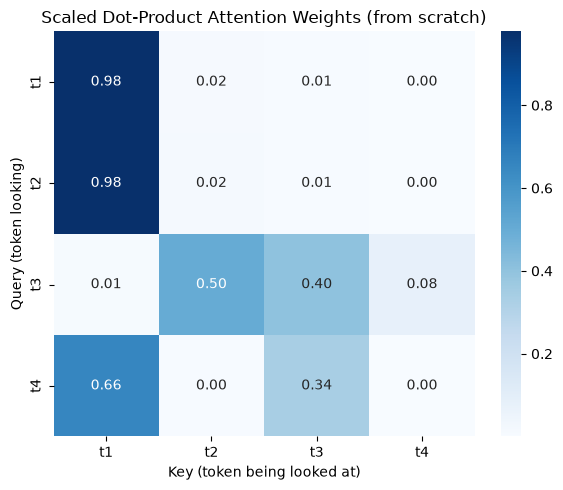

In [10]:
plt.figure(figsize=(6,5))

sns.heatmap(weights, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=["t1", "t2", "t3", "t4"], yticklabels=["t1", "t2", "t3", "t4"])

plt.title("Scaled Dot-Product Attention Weights (from scratch)")
plt.xlabel("Key (token being looked at)")
plt.ylabel("Query (token looking)")
plt.tight_layout()
plt.savefig("plots/attention_scratch.png", dpi=120)
plt.show()

- Q, K and V all have shape **(4, 8)**; the score matrix is **(4, 4)** because every token is compared with every token.
- Each **row sums to 1**, so every row is a probability distribution (how much a token attends to each token).
- The output has the **same shape as the input** (4, 8): each token is now a weighted mix of all Value vectors.

## 2.3 Why Divide by sqrt(d_k)?

In [11]:
def softmax_stats(d_k, scale, n_tokens=10):
    rng = np.random.default_rng(0)
    Q = rng.standard_normal((n_tokens, d_k))
    K = rng.standard_normal((n_tokens, d_k))

    scores = Q @ K.T
    if scale:
        scores = scores / np.sqrt(d_k)

    w = softmax(scores, axis=-1)
    max_prob = w.max(axis=1).mean()                              # average of the maximum probability per row
    entropy = (-(w * np.log(w + 1e-12)).sum(axis=1)).mean()      # average entropy per row
    return max_prob, entropy, scores.std()


rows = []
for d_k in [4, 256]:
    for scale in [False, True]:
        mp, ent, sd = softmax_stats(d_k, scale)
        rows.append([d_k, "WITH 1/sqrt(d_k)" if scale else "WITHOUT", round(sd, 2), round(mp, 3), round(ent, 3)])

pd.DataFrame(rows, columns=["d_k", "Scaling", "Std of scores", "Avg max probability", "Avg entropy"])

,d_k,Scaling,Std of scores,Avg max probability,Avg entropy
0,4,WITHOUT,1.84,0.375,1.640
1,4,WITH 1/sqrt(d_k),0.92,0.239,2.039
2,256,WITHOUT,15.98,0.971,0.099
3,256,WITH 1/sqrt(d_k),1.00,0.297,1.959


- **Without scaling**, the scores become larger when d_k grows (the standard deviation is about $\sqrt{d_k}$), so at **d_k = 256** the softmax becomes very sharp: the average maximum probability is close to **1** and the entropy is close to **0**.
- **With scaling**, the standard deviation stays near **1** for both d_k values, so the softmax stays smooth.
- At the small value **d_k = 4** the difference is small, but it becomes very large at d_k = 256.

### Why Divide by sqrt(d_k)?

- A dot product of two vectors with d_k random numbers has a variance of about **d_k**, so the scores **grow in magnitude with d_k**.
- Big scores push the softmax into a **saturated region** where one weight is almost 1 and the others are almost 0.
- In this region the **gradients are almost zero**, so the model cannot learn.
- Dividing by $\sqrt{d_k}$ brings the variance back to about **1**.

## 2.4 Self-Attention vs Luong Attention

In [12]:
rng = np.random.default_rng(1)

encoder_states = rng.standard_normal((5, 8))      # 5 encoder hidden states
decoder_state  = rng.standard_normal(8)           # 1 decoder hidden state

# Luong "dot" attention
luong_scores  = encoder_states @ decoder_state
luong_weights = softmax(luong_scores)
context       = luong_weights @ encoder_states

print("Scores  :", np.round(luong_scores, 3))
print("Weights :", np.round(luong_weights, 3), "| sum =", luong_weights.sum().round(3))
print("Context vector shape:", context.shape)

Scores  : [-0.138 -1.431 -0.04   5.668 -1.761]
Weights : [0.003 0.001 0.003 0.992 0.001] | sum = 1.0
Context vector shape: (8,)


- The decoder state "asks" all 5 encoder states and gets **5 weights that sum to 1**.
- The **context vector** (shape 8) is a weighted average of the encoder states.
- Here only **one** decoder state looks at the encoder states. In self-attention **every** token looks at every token.

## Luong Attention vs Self-Attention

| Feature | Luong Attention | Self-Attention |
|---------|-----------------|----------------|
| **Where Q, K, V come from** | Query = decoder state, Keys/Values = encoder states | Q, K and V all come from the **same sequence** |
| **What is attended over** | The decoder state looks at the encoder states | Every token looks at every token |
| **Needs an RNN?** | Yes (RNN encoder and decoder) | No |
| **Parallelism** | No (RNN steps are sequential) | Yes (whole sequence at once) |
| **Where it sits** | Between the encoder and the decoder | Inside every layer of the encoder / decoder |

## 2.5 Attention is Order-Blind

In [13]:
perm = [2, 0, 3, 1]                                   # a fixed shuffle of the 4 tokens

out_original, _, _ = self_attention(X, Wq, Wk, Wv)
out_shuffled, _, _ = self_attention(X[perm], Wq, Wk, Wv)

print("Output rows are the same rows in shuffled order:", np.allclose(out_shuffled, out_original[perm]))

Output rows are the same rows in shuffled order: True


- `np.allclose` returned **True**: shuffling the input tokens only shuffles the output rows in the same way.
- So self-attention **has no notion of position**. "dog bites man" and "man bites dog" would look the same to it.
- This is exactly why Task 3 needs **positional encoding**.

## 2.6 Verify Against a Real Model

In [14]:
sentence = "The movie was surprisingly good."
inputs = tok(sentence, return_tensors="pt")

with torch.no_grad():
    out = model(**inputs, output_hidden_states=True, output_attentions=True)

hidden_0 = out.hidden_states[0]                       # input of layer 0, shape (1, T, 768)
real_attn = out.attentions[0][0, 0].numpy()           # layer 0, head 0, shape (T, T)

layer0 = model.distilbert.transformer.layer[0].attention
print(layer0)

DistilBertSelfAttention(
  (q_lin): Linear(in_features=768, out_features=768, bias=True)
  (k_lin): Linear(in_features=768, out_features=768, bias=True)
  (v_lin): Linear(in_features=768, out_features=768, bias=True)
  (out_lin): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)


In [15]:
n_heads, head_dim = 12, 64

with torch.no_grad():
    q = layer0.q_lin(hidden_0)[0]                     # (T, 768)
    k = layer0.k_lin(hidden_0)[0]

T = q.shape[0]
q = q.reshape(T, n_heads, head_dim)[:, 0, :].numpy()  # head 0 -> (T, 64)
k = k.reshape(T, n_heads, head_dim)[:, 0, :].numpy()

my_attn = softmax(q @ k.T / np.sqrt(head_dim))        # no padding here, so no mask is needed

print("My attention matrix  :", my_attn.shape)
print("Real attention matrix:", real_attn.shape)
print("Match with np.allclose (1e-4):", np.allclose(my_attn, real_attn, atol=1e-4))
print("Maximum absolute difference  :", np.abs(my_attn - real_attn).max())

My attention matrix  : (8, 8)
Real attention matrix: (8, 8)
Match with np.allclose (1e-4): True
Maximum absolute difference  : 2.3104168467291686e-08


- The attention matrix that I calculated myself (layer 0, head 0) is **equal** to the one returned by DistilBERT. The maximum difference is extremely small.
- This proves that the real model **really uses** the equation `softmax(QK^T / sqrt(d_k))` with 12 heads of size 64, and that my NumPy version is correct.
- The input of layer 0 is `hidden_states[0]` (the embeddings), and the model applies its learned `q_lin` and `k_lin` projections to it.

# Task 3: Multi-Head Attention, Positional Encoding & Layer Normalization

**Objective:** See how several heads work, how position is added and how LayerNorm works.

**Expected output:** real attention heads, head entropy, positional encoding heatmaps and LayerNorm checks.

## 3.1 Multi-Head Attention

## Why Multi-Head Attention?

- One attention pattern is **not enough**: a word can relate to others in many ways (grammar, meaning, nearby words).
- With **h heads**, the model dimension is split into h smaller parts. For DistilBERT: **768 = 12 heads × 64**.
- Each head has its **own Q, K, V projections** and learns its **own attention pattern**.
- The heads are **concatenated** and mixed by an **output projection** (`out_lin`).
- The total computation stays **about the same** as one big head.

## 3.2 Extract and Plot Real Attention Heads

In [16]:
sentence = "The animal did not cross the street because it was too tired."
inputs = tok(sentence, return_tensors="pt")
tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])

with torch.no_grad():
    out = model(**inputs, output_attentions=True)

attentions = out.attentions

print("Number of layers :", len(attentions))
print("Shape per layer  :", attentions[0].shape, "= (batch, heads, tokens, tokens)")
print("Tokens           :", tokens)

Number of layers : 6
Shape per layer  : torch.Size([1, 12, 15, 15]) = (batch, heads, tokens, tokens)
Tokens           : ['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


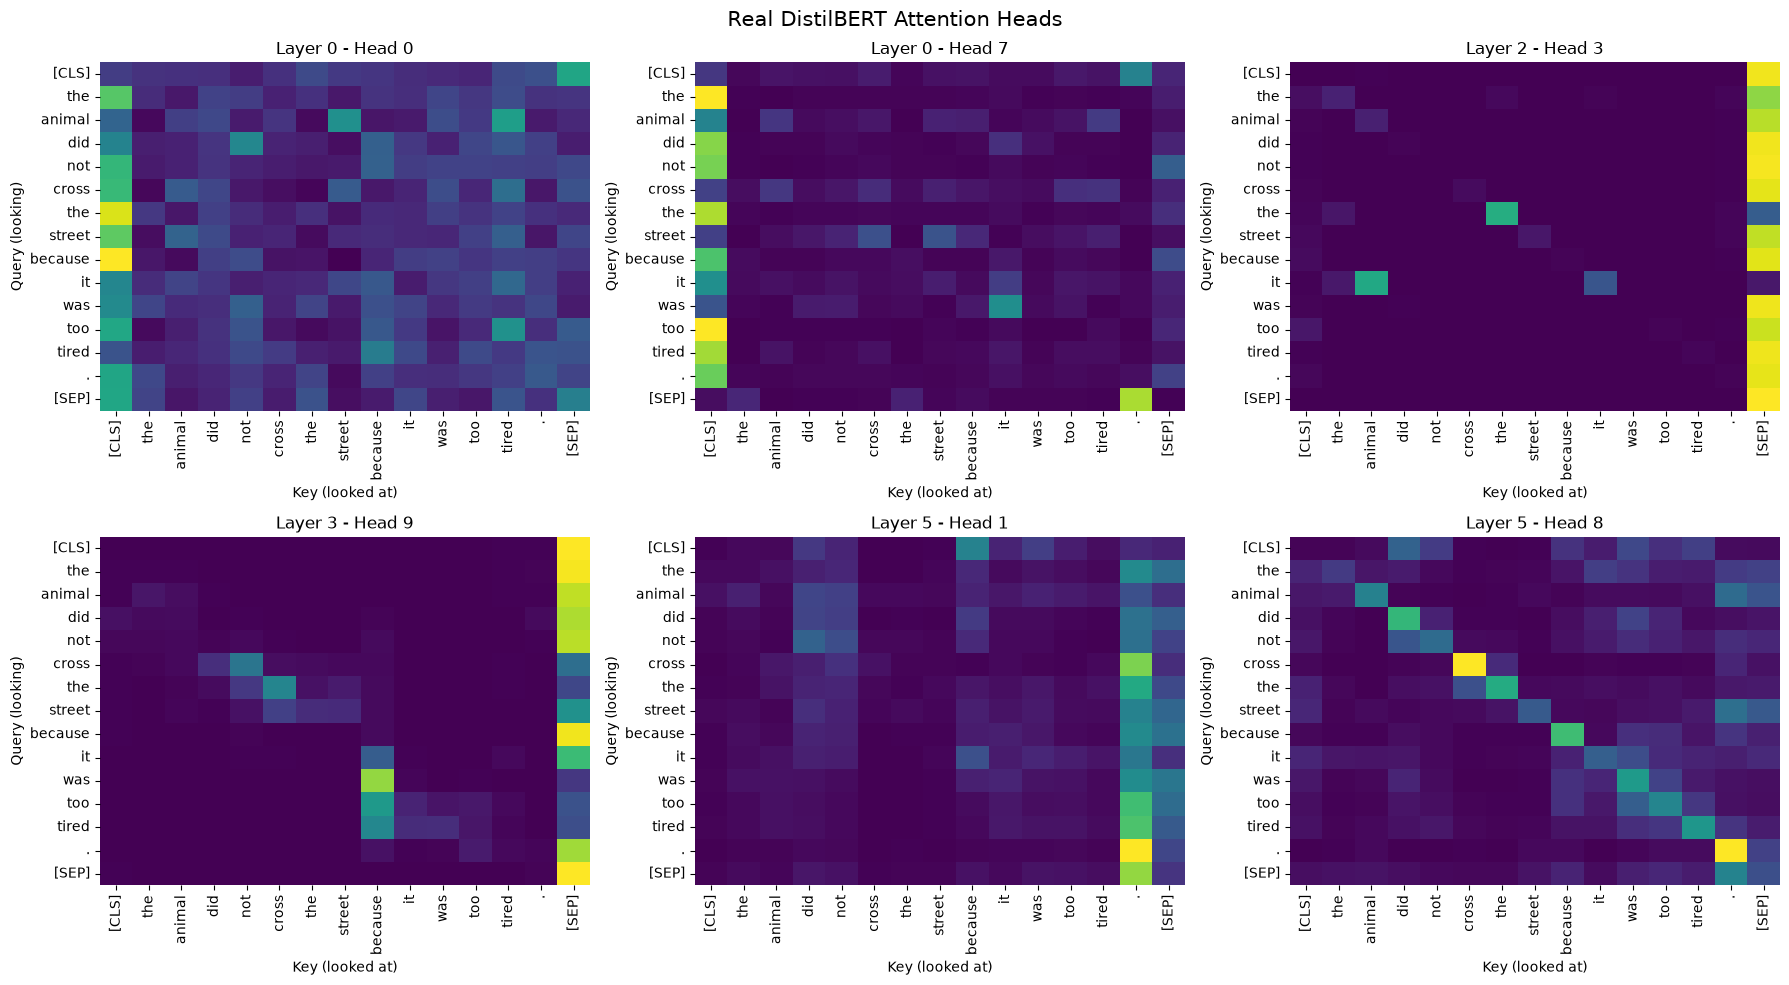

In [17]:
# 6 heads from different layers: (layer, head)
chosen = [(0, 0), (0, 7), (2, 3), (3, 9), (5, 1), (5, 8)]

plt.figure(figsize=(18,10))

for i, (layer, head) in enumerate(chosen, start=1):
    plt.subplot(2, 3, i)
    sns.heatmap(attentions[layer][0, head].numpy(), cmap="viridis",
                xticklabels=tokens, yticklabels=tokens, cbar=False)
    plt.title(f"Layer {layer} - Head {head}")
    plt.xlabel("Key (looked at)")
    plt.ylabel("Query (looking)")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)

plt.suptitle("Real DistilBERT Attention Heads", fontsize=15)
plt.tight_layout()
plt.savefig("plots/attention_heads.png", dpi=120)
plt.show()

- There are **6 layers** and each attention tensor has shape **(1, 12, tokens, tokens)**.
- Different heads show **different behaviours**. Look for patterns like these in your own plot:
  - A head that attends mostly to the **previous or next token** (a bright line next to the diagonal).
  - A head that sends most attention to **[CLS] or [SEP]** (a bright vertical column).
  - A head in a later layer that connects **"it" with "animal"** or another noun.
- This shows that heads **specialise** instead of all doing the same thing.

## 3.3 Head Diversity Measurement

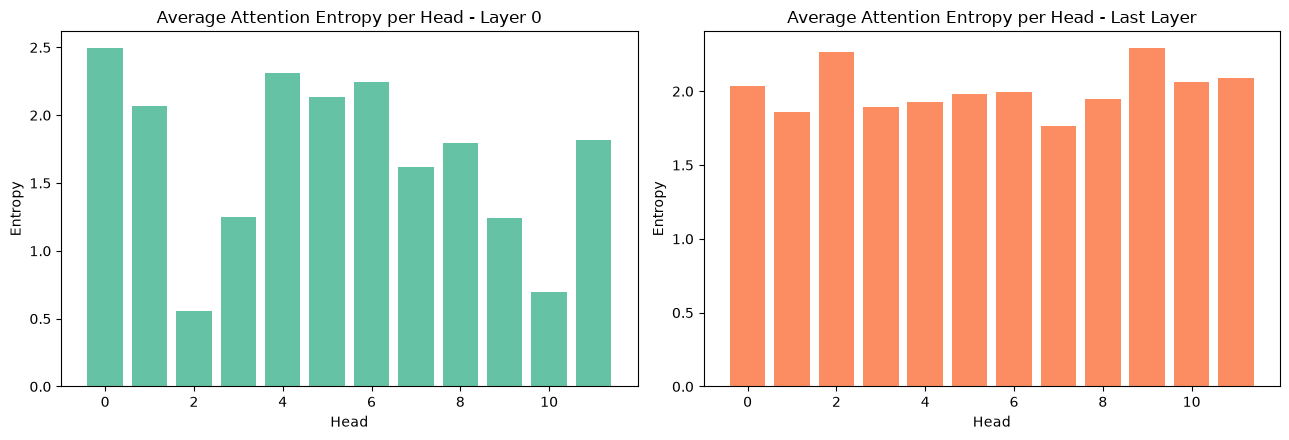

Mean entropy, layer 0   : 1.686
Mean entropy, last layer: 2.01


In [18]:
def head_entropy(attn):
    # attn shape: (heads, T, T) -> average entropy per head
    ent = -(attn * torch.log(attn + 1e-12)).sum(dim=-1)      # entropy of every row
    return ent.mean(dim=-1).numpy()                          # average over the rows


ent_first = head_entropy(attentions[0][0])
ent_last  = head_entropy(attentions[-1][0])

plt.figure(figsize=(13,4.5))

plt.subplot(1,2,1)
plt.bar(range(12), ent_first, color="#66C2A5")
plt.title("Average Attention Entropy per Head - Layer 0")
plt.xlabel("Head")
plt.ylabel("Entropy")

plt.subplot(1,2,2)
plt.bar(range(12), ent_last, color="#FC8D62")
plt.title("Average Attention Entropy per Head - Last Layer")
plt.xlabel("Head")
plt.ylabel("Entropy")

plt.tight_layout()
plt.show()

print("Mean entropy, layer 0   :", ent_first.mean().round(3))
print("Mean entropy, last layer:", ent_last.mean().round(3))

- **Low entropy** means a focused head (looks at few tokens); **high entropy** means a spread-out head.
- The heads inside one layer have **different entropies**, so they behave differently.
- Compare the two means: in this single sentence the early and the late layer look different, but this is only **one sentence**, so the claim should stay modest.

## 3.4 Sinusoidal Positional Encoding from Scratch

PE shape: (50, 128)


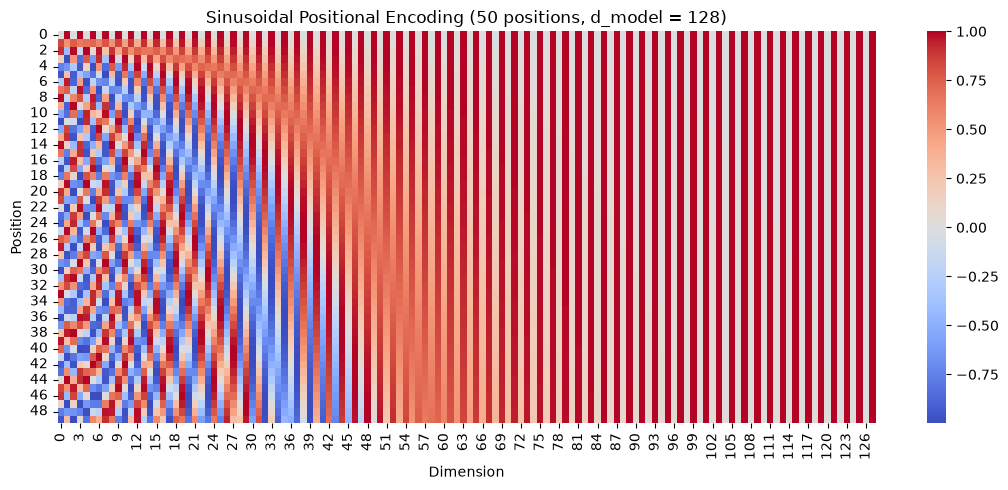

In [19]:
def positional_encoding(n_positions, d_model):
    pe = np.zeros((n_positions, d_model))
    pos = np.arange(n_positions)[:, np.newaxis]                    # (n, 1)
    i = np.arange(0, d_model, 2)[np.newaxis, :]                    # (1, d/2)
    angle = pos / np.power(10000, i / d_model)

    pe[:, 0::2] = np.sin(angle)      # even dimensions
    pe[:, 1::2] = np.cos(angle)      # odd dimensions
    return pe


PE = positional_encoding(50, 128)
print("PE shape:", PE.shape)

plt.figure(figsize=(11,5))

sns.heatmap(PE, cmap="coolwarm", center=0)

plt.title("Sinusoidal Positional Encoding (50 positions, d_model = 128)")
plt.xlabel("Dimension")
plt.ylabel("Position")
plt.tight_layout()
plt.savefig("plots/positional_encoding.png", dpi=120)
plt.show()

- The **left dimensions** change quickly from one position to the next (high frequency), and the **right dimensions** change slowly (low frequency).
- Every row (position) has a **different pattern**, like a unique "barcode" for each position.

### Why Sines and Cosines of Different Frequencies?

- Every position gets a **unique pattern**, so the model can tell positions apart.
- Because there are many frequencies, the model can easily learn **relative offsets** ("3 words before"), since $PE_{pos+k}$ can be written as a linear function of $PE_{pos}$.
- The formula also works for positions longer than those seen in training.

$$
PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right) \qquad PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
$$

## 3.5 Position Makes Identical Words Different

In [20]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

rng = np.random.default_rng(5)
word = rng.standard_normal(128)                 # one word embedding

PE100 = positional_encoding(100, 128)

word_pos3  = word + PE100[3]
word_pos20 = word + PE100[20]

print("Cosine similarity WITHOUT positional encoding:", cosine(word, word))
print("Cosine similarity WITH positional encoding   :", round(cosine(word_pos3, word_pos20), 4))

Cosine similarity WITHOUT positional encoding: 0.9999999999999999
Cosine similarity WITH positional encoding   : 0.8202


- Without PE the same word at two positions is **exactly the same vector** (similarity = 1.0).
- With PE the two vectors become **different** (similarity below 1.0), so the model can know *where* the word is.
- Together with Task 2.5: self-attention is order-blind, but after **adding PE to the embeddings** the shuffled sentence is no longer identical, so the **order-blindness is removed**.

## 3.6 Learned Positional Embeddings in a Real Model

Position embedding shape: (512, 768)


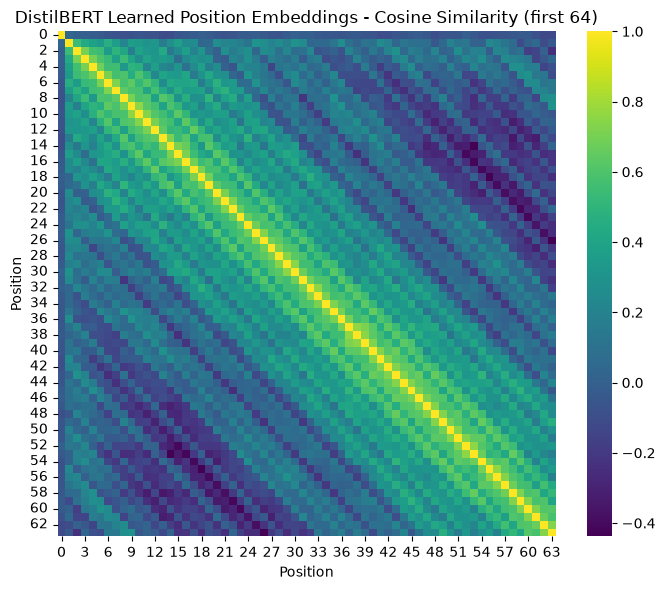

In [21]:
pos_weights = model.distilbert.embeddings.position_embeddings.weight.detach().numpy()
print("Position embedding shape:", pos_weights.shape)

first64 = pos_weights[:64]
norm = first64 / np.linalg.norm(first64, axis=1, keepdims=True)
cos_matrix = norm @ norm.T

plt.figure(figsize=(7,6))

sns.heatmap(cos_matrix, cmap="viridis")

plt.title("DistilBERT Learned Position Embeddings - Cosine Similarity (first 64)")
plt.xlabel("Position")
plt.ylabel("Position")
plt.tight_layout()
plt.show()

- The table has shape **(512, 768)**: one learned vector for each of the 512 positions.
- The heatmap is brightest on the **diagonal**, and positions that are **close to each other are more similar**. So the model learned a sense of distance by itself.
- BERT-style models **learn** their position vectors instead of using sinusoids.
- Since there are only **512 position vectors**, the model cannot read more than **512 tokens**. This is the origin of the context-length limit.
- T5 uses **relative position biases** instead (we meet it in Task 5).

## 3.7 Layer Normalization from Scratch

In [22]:
def layer_norm(x, gamma=1.0, beta=0.0, eps=1e-5):
    mean = x.mean(axis=-1, keepdims=True)           # mean over the FEATURES of each token
    var  = x.var(axis=-1, keepdims=True)
    return gamma * (x - mean) / np.sqrt(var + eps) + beta


rng = np.random.default_rng(3)
M = rng.standard_normal((4, 8)) * 5 + 10            # 4 tokens x 8 features (not normalised)

ln_out = layer_norm(M)

print("Per-token mean:", np.round(ln_out.mean(axis=1), 6))
print("Per-token std :", np.round(ln_out.std(axis=1), 4))

# Compare with PyTorch
torch_ln = torch.nn.LayerNorm(8)
torch_out = torch_ln(torch.tensor(M, dtype=torch.float32))

print("\nMatches torch.nn.LayerNorm:", torch.allclose(torch_out, torch.tensor(ln_out, dtype=torch.float32), atol=1e-5))

Per-token mean: [ 0.  0. -0. -0.]
Per-token std : [1. 1. 1. 1.]

Matches torch.nn.LayerNorm: True


- After LayerNorm, **every token vector has mean about 0 and standard deviation about 1**, even though the input values were around 10.
- My NumPy LayerNorm gives the **same result** as `torch.nn.LayerNorm` (`torch.allclose` is True).
- The mean and variance are taken **over the 8 features of one single token**, not over other tokens.

## 3.8 LayerNorm vs BatchNorm

In [23]:
# BatchNorm: normalise each FEATURE across the 4 tokens
bn_out = (M - M.mean(axis=0, keepdims=True)) / np.sqrt(M.var(axis=0, keepdims=True) + 1e-5)

print("BatchNorm - per-FEATURE mean (about 0):", np.round(bn_out.mean(axis=0), 4))
print("BatchNorm - per-TOKEN   mean (NOT 0)  :", np.round(bn_out.mean(axis=1), 4))
print("BatchNorm - per-TOKEN   std  (NOT 1)  :", np.round(bn_out.std(axis=1), 4))

BatchNorm - per-FEATURE mean (about 0): [-0.  0.  0. -0. -0.  0. -0.  0.]
BatchNorm - per-TOKEN   mean (NOT 0)  : [-0.5169 -0.3439  0.4902  0.3706]
BatchNorm - per-TOKEN   std  (NOT 1)  : [1.1301 0.8043 0.9806 0.5928]


In [24]:
ln_layer = model.distilbert.embeddings.LayerNorm

print("DistilBERT embedding LayerNorm gamma (weight) shape:", ln_layer.weight.shape)
print("DistilBERT embedding LayerNorm beta (bias) shape   :", ln_layer.bias.shape)
print("First 5 gamma values:", ln_layer.weight[:5].detach().numpy().round(3))
print("First 5 beta values :", ln_layer.bias[:5].detach().numpy().round(3))

DistilBERT embedding LayerNorm gamma (weight) shape: torch.Size([768])
DistilBERT embedding LayerNorm beta (bias) shape   : torch.Size([768])
First 5 gamma values: [0.845 0.797 0.733 0.759 0.801]
First 5 beta values : [ 0.044  0.061  0.069  0.087 -0.058]


- BatchNorm makes each **feature** normal across the tokens, but the **per-token** mean and standard deviation are **not** 0 and 1.
- LayerNorm normalises each **token** on its own, so it does not depend on the other tokens.
- The LayerNorm of DistilBERT has **768 gamma and 768 beta values**.

## LayerNorm vs BatchNorm

| Feature | BatchNorm (PR 2) | LayerNorm |
|---------|------------------|-----------|
| **Normalised over** | Each feature across the batch | The features of one single token |
| **Depends on batch size** | Yes (small batches give noisy statistics) | No |
| **Variable-length sequences and padding** | Problematic (padding changes the statistics) | No problem |
| **Training vs inference** | Needs running averages | Same calculation in both |
| **Used in** | CNNs and ANNs on tables | Transformers |

- **Gamma (γ)** is a learned **scale** and **beta (β)** is a learned **shift** that are applied after normalising, so the model can undo the normalisation when it is useful.
- Transformers use LayerNorm because sequences have **different lengths with padding** and the batch size can be small or even 1 at inference.

# Task 4: Transformer Encoder Architecture & Masked Self-Attention

**Objective:** Read the real encoder, see where the parameters are and compare bidirectional with causal attention.

**Expected output:** module table, parameter chart, fill-mask results, bidirectional and causal heatmaps, padding-mask check.

## 4.1 Encoder Architecture

## The Encoder Block

Input embeddings + positional information go through **N stacked blocks**. Each block contains:

1. **Multi-head self-attention**
2. **Residual connection + Layer Normalization** (add and norm)
3. **Position-wise feed-forward network** (expand → non-linearity → project back)
4. **Residual connection + Layer Normalization**

- DistilBERT has **6 such layers**.
- "Encoder" means that **every token can see every other token in both directions** (left and right).

## 4.2 Print and Read the Real Encoder

In [25]:
print(model.distilbert)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

## Module Names in DistilBERT

| Part | Module name |
|------|-------------|
| **Token embedding** | `embeddings.word_embeddings` |
| **Position embedding** | `embeddings.position_embeddings` |
| **Embedding LayerNorm** | `embeddings.LayerNorm` |
| **Attention block** | `transformer.layer.N.attention` with `q_lin`, `k_lin`, `v_lin`, `out_lin` |
| **Feed-forward block** | `transformer.layer.N.ffn` with `lin1`, `lin2` and the activation (GELU) |
| **Two LayerNorms per block** | `sa_layer_norm` (after attention) and `output_layer_norm` (after feed-forward) |

- The feed-forward network **expands 768 → 3072** (`lin1`) and then **projects back 3072 → 768** (`lin2`).

## 4.3 Where Do the Parameters Live?

In [26]:
groups = {"Embeddings": 0, "Attention": 0, "Feed-forward": 0, "Layer norms": 0, "Classification head": 0}

for name, p in model.named_parameters():
    n = p.numel()
    if "LayerNorm" in name or "layer_norm" in name:
        groups["Layer norms"] += n
    elif "embeddings" in name:
        groups["Embeddings"] += n
    elif "attention" in name:
        groups["Attention"] += n
    elif "ffn" in name:
        groups["Feed-forward"] += n
    else:
        groups["Classification head"] += n

total = sum(groups.values())

param_table = pd.DataFrame({
    "Component": list(groups.keys()),
    "Parameters": list(groups.values()),
    "Share (%)": [round(100 * v / total, 2) for v in groups.values()]
})

display(param_table)
print("Total:", total, "| matches model total:", total == total_params)

,Component,Parameters,Share (%)
0,Embeddings,23834112,35.60
1,Attention,14174208,21.17
2,Feed-forward,28334592,42.32
3,Layer norms,19968,0.03
4,Classification head,592130,0.88


Total: 66955010 | matches model total: True


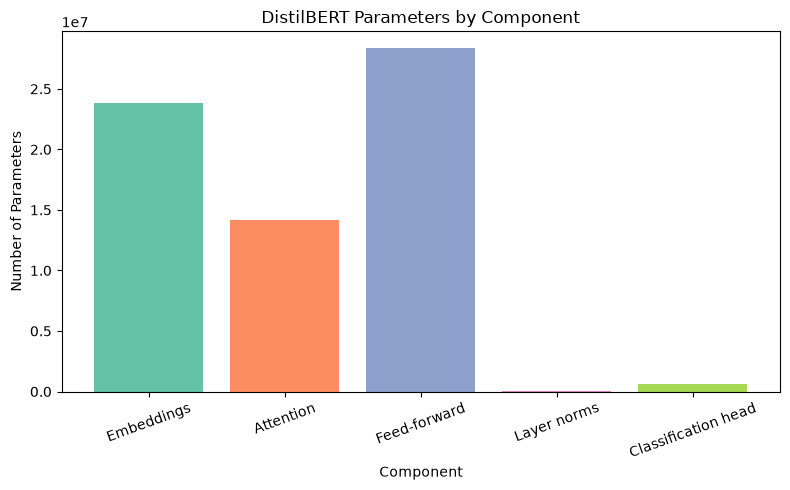

In [27]:
plt.figure(figsize=(8,5))

plt.bar(param_table["Component"], param_table["Parameters"], color=sns.color_palette("Set2"))

plt.title("DistilBERT Parameters by Component")
plt.xlabel("Component")
plt.ylabel("Number of Parameters")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

- The **feed-forward networks** hold the **largest share** of the parameters (about 40% of the model), followed by the **embeddings** (about a third) and then the **attention** layers (about a fifth). The layer norms and the head are tiny.
- This tells us that most of the "stored knowledge" is in the **feed-forward layers** and the **embedding table**, while attention mostly decides **which information to move** between tokens.

## 4.4 Use the Encoder: Fill-Mask

In [28]:
fill = pipeline("fill-mask", model="distilbert-base-uncased")

masked_sentences = [
    "The capital of France is [MASK].",
    "I went to the [MASK] to buy some bread.",
    "She was very [MASK] because she won the prize.",
]

for s in masked_sentences:
    print("\n", s)
    for r in fill(s, top_k=3):
        print(f"   {r['token_str']:12s} score = {r['score']:.4f}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


 The capital of France is [MASK].
   marseille    score = 0.1427
   nantes       score = 0.0902
   toulouse     score = 0.0881

 I went to the [MASK] to buy some bread.
   bakery       score = 0.2565
   market       score = 0.1430
   kitchen      score = 0.0992

 She was very [MASK] because she won the prize.
   lucky        score = 0.1745
   honored      score = 0.1141
   popular      score = 0.0769


- The model predicted sensible words for the masked position (for example **paris** for the capital of France).
- The best guess uses the words **on both sides** of the mask: "went to the ___ to buy some bread" needs the words after the mask ("buy some bread") to guess "store" or "bakery".
- This is the **bidirectional encoder** behaviour.

## 4.5 Bidirectional Attention Heatmap

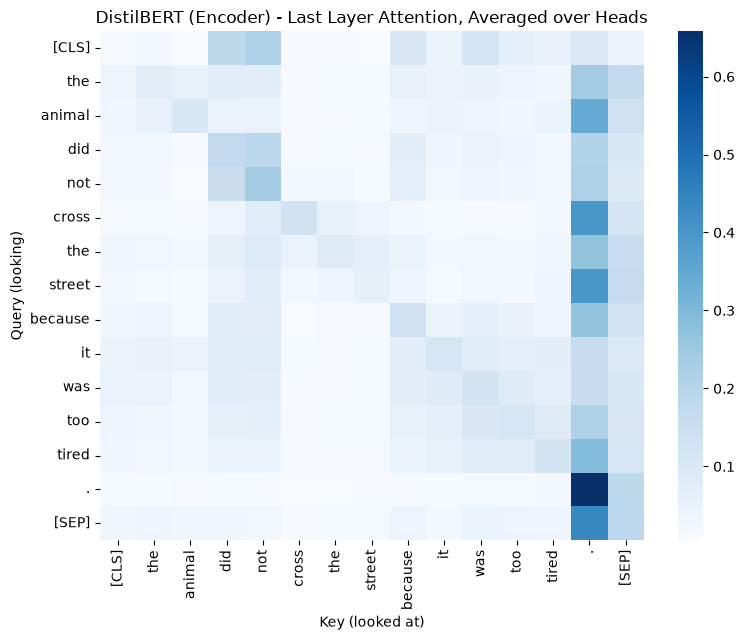

Total weight ABOVE the diagonal: 8.523
Total weight BELOW the diagonal: 4.138


In [29]:
last_layer_avg = attentions[-1][0].mean(dim=0).numpy()       # average over the 12 heads, last layer

plt.figure(figsize=(8,6.5))

sns.heatmap(last_layer_avg, cmap="Blues", xticklabels=tokens, yticklabels=tokens)

plt.title("DistilBERT (Encoder) - Last Layer Attention, Averaged over Heads")
plt.xlabel("Key (looked at)")
plt.ylabel("Query (looking)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

upper = np.triu(last_layer_avg, k=1).sum()
lower = np.tril(last_layer_avg, k=-1).sum()

print("Total weight ABOVE the diagonal:", round(float(upper), 3))
print("Total weight BELOW the diagonal:", round(float(lower), 3))

- There are **non-zero weights both above and below the diagonal**: each token looks at tokens on its left **and** on its right.
- This is allowed in an encoder, but **not** in a language model that must predict the next word, because it would **see the answer**. That is why the decoder needs **masked self-attention**.

## 4.6 Masked (Causal) Self-Attention from Scratch

In [30]:
n = 6
rng = np.random.default_rng(7)

X6 = rng.standard_normal((n, 8))
Wq6, Wk6, Wv6 = [rng.standard_normal((8, 8)) for _ in range(3)]

# Causal mask: -infinity above the diagonal, 0 on and below it
causal_mask = np.triu(np.full((n, n), -np.inf), k=1)
print("Causal mask:\n", causal_mask)

out_causal, w_causal, _ = self_attention(X6, Wq6, Wk6, Wv6, mask=causal_mask)

print("\nLower-triangular:", np.allclose(w_causal, np.tril(w_causal)))
print("Row sums        :", w_causal.sum(axis=1))

Causal mask:
 [[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]

Lower-triangular: True
Row sums        : [1. 1. 1. 1. 1. 1.]


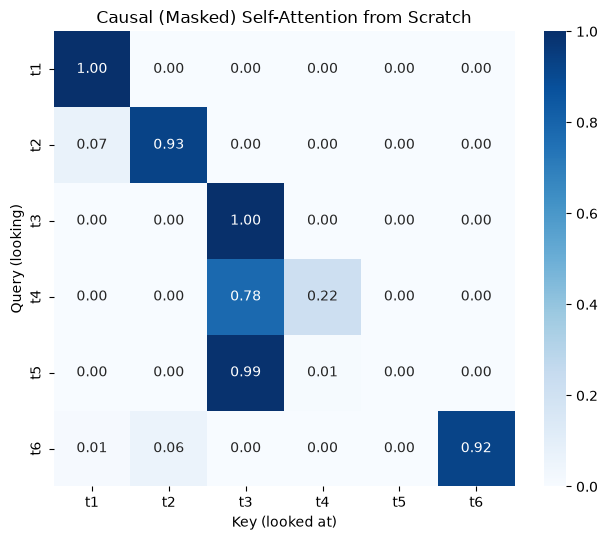

In [31]:
plt.figure(figsize=(6.5,5.5))

sns.heatmap(w_causal, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=[f"t{i+1}" for i in range(n)], yticklabels=[f"t{i+1}" for i in range(n)])

plt.title("Causal (Masked) Self-Attention from Scratch")
plt.xlabel("Key (looked at)")
plt.ylabel("Query (looking)")
plt.tight_layout()
plt.savefig("plots/causal_mask.png", dpi=120)
plt.show()

- The attention matrix is **lower-triangular**: token *t* can only look at tokens 1 to *t*, never at the future.
- Every row still **sums to 1**. The first token can only attend to itself (weight = 1.0).

### Why Add -Infinity Before the Softmax?

- $e^{-\infty} = 0$, so the masked positions get **exactly zero weight** and the remaining weights are still **normalised to sum to 1**.
- If we zeroed the weights **after** the softmax, the rows would **no longer sum to 1** and the model would have already used the future tokens when computing the probabilities.

## 4.7 Causal Mask in a Real Decoder (GPT-2)

In [32]:
from transformers import AutoModelForCausalLM, AutoTokenizer

gpt2_tok = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2", attn_implementation="eager")
gpt2.eval()

g_inputs = gpt2_tok("The animal did not cross the street because it was tired.", return_tensors="pt")
g_tokens = gpt2_tok.convert_ids_to_tokens(g_inputs["input_ids"][0])

with torch.no_grad():
    g_out = gpt2(**g_inputs, output_attentions=True)

gpt_attn = g_out.attentions[-1][0, 0].numpy()          # last layer, head 0

print("Max value above the diagonal:", np.triu(gpt_attn, k=1).max())
print("All entries above the diagonal are (almost) zero:", np.triu(gpt_attn, k=1).max() < 1e-6)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Max value above the diagonal: 0.0
All entries above the diagonal are (almost) zero: True


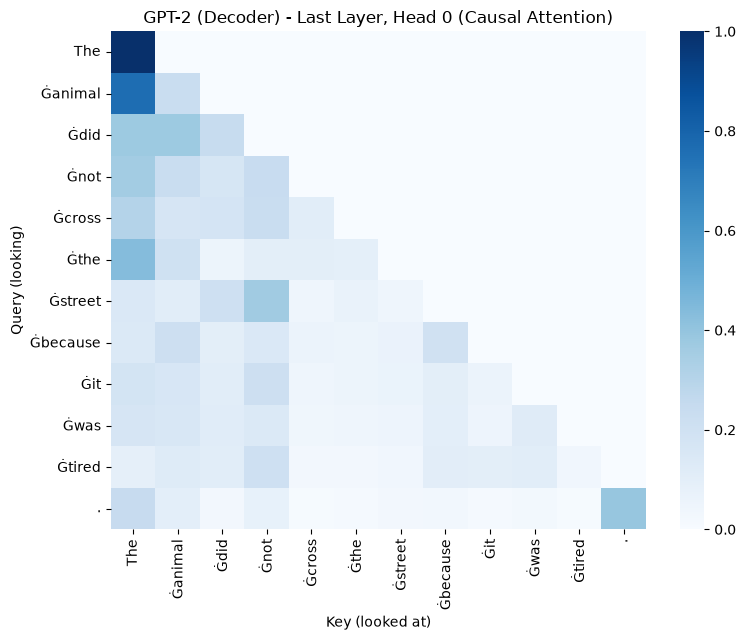

In [33]:
plt.figure(figsize=(8,6.5))

sns.heatmap(gpt_attn, cmap="Blues", xticklabels=g_tokens, yticklabels=g_tokens)

plt.title("GPT-2 (Decoder) - Last Layer, Head 0 (Causal Attention)")
plt.xlabel("Key (looked at)")
plt.ylabel("Query (looking)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

- The real GPT-2 attention is **lower-triangular**: the values above the diagonal are **zero** (the check is True).
- Compared with the DistilBERT plot in 4.5, which has weights on both sides of the diagonal, GPT-2 can only look **backwards**.
- This matches my NumPy causal mask from 4.6.

## 4.8 Padding Mask vs Causal Mask

In [34]:
pad_batch = tok(["I loved it.", "The movie was long, slow and honestly a little bit boring."],
                padding=True, return_tensors="pt")

with torch.no_grad():
    pad_out = model(**pad_batch, output_attentions=True)

attn_last = pad_out.attentions[-1]                    # (2, 12, T, T)
mask = pad_batch["attention_mask"][0]                 # mask of the SHORT sentence
pad_positions = (mask == 0).nonzero().flatten()

print("Attention mask of sentence 1:", mask.tolist())
print("Padding positions           :", pad_positions.tolist())

received = attn_last[0][:, :, pad_positions]          # weights received by padding positions
print("\nMaximum attention received by a padding token:", received.max().item())

Attention mask of sentence 1: [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Padding positions           : [6, 7, 8, 9, 10, 11, 12, 13, 14]

Maximum attention received by a padding token: 0.0


- The short sentence has padding at the end, and the attention that **padding positions receive is practically zero**.
- So the `attention_mask` works: the model **ignores the padding** and the padded batch gives the same result as the sentence alone.

## Padding Mask vs Causal Mask

| Feature | Padding Mask | Causal Mask |
|---------|--------------|-------------|
| **Purpose** | Ignore the [PAD] tokens | Stop a token from seeing future tokens |
| **Shape pattern** | Whole **columns** of the padded positions are blocked | **Upper triangle** is blocked |
| **Depends on the data** | Yes (depends on sentence length) | No (always the same triangle) |
| **Model families** | All (BERT, GPT-2, T5) when padding is used | Decoder-only (GPT-2) and the decoder of T5 |

# Task 5: Cross-Attention, Decoder Architecture & Inference

**Objective:** Understand the decoder, cross-attention and how text is generated token by token.

**Expected output:** translation and summary, cross-attention heatmap, manual greedy loop, decoding strategies and KV-cache timing.

## 5.1 Decoder Architecture

## The Decoder Block

The original Transformer decoder block has:

1. **Masked multi-head self-attention** → add and norm
2. **Cross-attention** over the encoder output → add and norm
3. **Feed-forward** → add and norm

At the top there is a **linear layer and a softmax over the vocabulary** that gives the probability of the next token.

## The Three Model Families

- **Encoder-only (DistilBERT / BERT):** understands text (classification, fill-mask). Bidirectional attention.
- **Decoder-only (GPT-2):** generates text. It **drops cross-attention** and keeps only masked self-attention.
- **Encoder-decoder (T5):** keeps **both** and is used for translation and summarisation.

## 5.2 Cross-Attention

## What is Cross-Attention?

- In cross-attention the **Queries come from the DECODER**, while the **Keys and Values come from the ENCODER output**.
- This lets the decoder **look at the source sentence while it writes the target sentence**. For example, when it writes the French word "maison", it can look at the English word "house".
- It is the same idea as **Luong attention** (Task 2.4: decoder state looks at encoder states), but built from Q, K, V and without any RNN.

## 5.3 Run an Encoder-Decoder Model

In [35]:
translator = pipeline("translation_en_to_fr", model="t5-small")

english_sentences = [
    "The weather is beautiful today.",
    "I would like to order a cup of coffee.",
    "Artificial intelligence is changing the world.",
]

for s in english_sentences:
    print("EN:", s)
    print("FR:", translator(s)[0]["translation_text"], "\n")

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

KeyError: 'The task translation_en_to_fr has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

In [36]:
summarizer = pipeline("summarization", model="t5-small")

# TIP: replace this paragraph with a real news article of your choice (150-300 words)
paragraph = """
Cities around the world are investing heavily in public transport to reduce traffic and air pollution.
In many places, old diesel buses are being replaced with electric ones, and new tram and metro lines are being built
to connect the suburbs with the city centre. Officials say that cheaper and more reliable transport encourages people
to leave their cars at home, which cuts the number of vehicles on the road during rush hour. Some cities have also
introduced congestion charges, asking drivers to pay a fee to enter the busiest districts, and the money is used to
improve buses and cycling lanes. Critics argue that these projects are expensive and take many years to finish, and that
people who live far from the stations may not benefit at all. Supporters reply that the long-term savings in health costs,
fuel and lost working time are much larger than the construction costs. Experts also point out that safe bicycle paths
and wider pavements make cities more pleasant, and that the best results come when several measures are used together
rather than a single big project. Many cities now publish yearly reports to show whether air quality is really improving.
"""

summary = summarizer(paragraph.strip().replace("\n", " "), max_length=60, min_length=20)[0]["summary_text"]

print("Summary:", summary)
print("\nInput length  :", len(paragraph.split()), "words")
print("Summary length:", len(summary.split()), "words")

KeyError: 'The task summarization has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

- T5-small translated the 3 sentences into French. The result is understandable but **not perfect**, because t5-small is a very small model.
- The summariser compressed the paragraph into a much shorter text (between 20 and 60 tokens).
- One model (T5) can do both tasks, because T5 turns **every task into text-to-text** with a prefix like "translate English to French:" or "summarize:". The pipeline adds this prefix for us.

## 5.4 Extract and Plot Cross-Attention

In [ ]:
from transformers import T5ForConditionalGeneration

t5_tok = AutoTokenizer.from_pretrained("t5-small")
t5 = T5ForConditionalGeneration.from_pretrained("t5-small", attn_implementation="eager")
t5.eval()

source = "translate English to French: The house is small."
target = "La maison est petite."

input_ids = t5_tok(source, return_tensors="pt").input_ids
labels    = t5_tok(target, return_tensors="pt").input_ids

with torch.no_grad():
    t5_out = t5(input_ids=input_ids, labels=labels, output_attentions=True)

cross = t5_out.cross_attentions[-1][0].mean(dim=0).numpy()       # last decoder layer, average over 8 heads

src_tokens = t5_tok.convert_ids_to_tokens(input_ids[0])
tgt_tokens = t5_tok.convert_ids_to_tokens(labels[0])

print("Cross-attention shape (output tokens x input tokens):", cross.shape)
print("Input tokens :", src_tokens)
print("Output tokens:", tgt_tokens)

In [ ]:
plt.figure(figsize=(10,5))

sns.heatmap(cross, cmap="Blues", annot=True, fmt=".2f", xticklabels=src_tokens, yticklabels=tgt_tokens)

plt.title("T5-small Cross-Attention (last decoder layer, average of 8 heads)")
plt.xlabel("Input tokens (English, from the encoder)")
plt.ylabel("Output tokens (French, from the decoder)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("plots/cross_attention.png", dpi=120)
plt.show()

- **Rows** are the French output tokens (decoder = Queries) and **columns** are the English input tokens (encoder = Keys and Values).
- Look at which English word each French word attends to most. A sensible alignment would be, for example, **"maison" → "house"** and **"petite" → "small"**.
- The alignment may not be perfectly clean: in the last layer and when averaging 8 heads, some words attend strongly to the end token `</s>` or to the prefix, because attention is also used for other jobs than word alignment.
- Still, the plot shows that **the decoder looks at the source sentence while writing the translation**.

## 5.5 Inference is Autoregressive - Manual Loop

In [37]:
prompt = "Artificial intelligence will"
ids = gpt2_tok(prompt, return_tensors="pt").input_ids

# My own greedy decoding loop
manual_ids = ids.clone()

with torch.no_grad():
    for step in range(20):
        logits = gpt2(manual_ids).logits[:, -1, :]                  # scores for the NEXT token only
        next_id = torch.argmax(logits, dim=-1, keepdim=True)        # pick the most probable token
        manual_ids = torch.cat([manual_ids, next_id], dim=1)        # feed it back as input

manual_text = gpt2_tok.decode(manual_ids[0])
print("My loop      :", manual_text)

# The same with model.generate
with torch.no_grad():
    gen_ids = gpt2.generate(ids, max_new_tokens=20, do_sample=False, pad_token_id=gpt2_tok.eos_token_id)

gen_text = gpt2_tok.decode(gen_ids[0])
print("model.generate:", gen_text)

print("\nIdentical output:", manual_text == gen_text)

My loop      : Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
model.generate: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Identical output: True


- My own loop and `model.generate()` give the **identical text**.
- A decoder generates **ONE token at a time**: it predicts the next token from the last position, appends it to the input and runs again.
- This is **autoregressive** generation, and it is the reason why generation is slower than classification.

## 5.6 Decoding Strategies

In [38]:
def generate_text(seed=None, **kwargs):
    if seed is not None:
        torch.manual_seed(seed)
    with torch.no_grad():
        out = gpt2.generate(ids, max_new_tokens=40, pad_token_id=gpt2_tok.eos_token_id, **kwargs)
    return gpt2_tok.decode(out[0], skip_special_tokens=True)


rows = [
    ["Greedy", "-", generate_text(do_sample=False)],
    ["Beam search (5 beams)", "-", generate_text(num_beams=5, early_stopping=True, do_sample=False)],
    ["Sampling, temperature 0.7", "seed 1", generate_text(seed=1, do_sample=True, temperature=0.7, top_k=0)],
    ["Sampling, temperature 0.7", "seed 2", generate_text(seed=2, do_sample=True, temperature=0.7, top_k=0)],
    ["Sampling, temperature 1.5", "seed 1", generate_text(seed=1, do_sample=True, temperature=1.5, top_k=0)],
    ["Sampling, temperature 1.5", "seed 2", generate_text(seed=2, do_sample=True, temperature=1.5, top_k=0)],
    ["Top-k 50 + top-p 0.9", "seed 1", generate_text(seed=1, do_sample=True, top_k=50, top_p=0.9)],
]

pd.set_option("display.max_colwidth", 200)
pd.DataFrame(rows, columns=["Strategy", "Seed", "Generated text"])

,Strategy,Seed,Generated text
0,Greedy,-,"Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time.\n\n""We're going to be able to"
1,Beam search (5 beams),-,"Artificial intelligence will be the next big thing, and it's going to take a lot of work to get there.\n\n""I think it's going to take a lot of work to get there,"" he said"
2,"Sampling, temperature 0.7",seed 1,"Artificial intelligence will help us shape the future of the world.\n\nI am really excited about the future of AI. It is already possible to solve problems of intelligence, computation, and commun..."
3,"Sampling, temperature 0.7",seed 2,Artificial intelligence will not be able to solve problems that have never been solved.\n\nThe researchers note that the story of the self-driving car is like a tale of two halves: one is a self-d...
4,"Sampling, temperature 1.5",seed 1,"Artificial intelligence will upset inertia in difficult news ones. Countries humans would respect assimil c about every trial, scaven- Detection organizations from the above won % of dislressed or..."
5,"Sampling, temperature 1.5",seed 2,Artificial intelligence will not similarly distress down that angry increase paradigm and presume elsear characterShell pervasive strandsUpon childinitiality gradient spweet votingIn acid GUI libr...
6,Top-k 50 + top-p 0.9,seed 1,"Artificial intelligence will help with our search, and perhaps even help us decide which products to buy and which ones not to buy at the moment. I suspect this technology will have its future in ..."


- **Greedy** and **beam search** are deterministic: the same prompt always gives the same text. They often **repeat** phrases.
- **Temperature 0.7** gives text that is fairly safe, and the two seeds give **similar** texts.
- **Temperature 1.5** makes the text much more **random and sometimes nonsense**, and the two seeds give very different texts.
- **Top-k + top-p** keeps only the likely tokens, so it is creative but still readable.

### How Do Temperature, Top-k and Top-p Change the Output?

- **Temperature** divides the logits before the softmax: **low** (below 1) makes the distribution sharper (safer, more repetition), **high** (above 1) makes it flatter (more random).
- **Top-k** keeps only the *k* most probable tokens and samples from them.
- **Top-p (nucleus)** keeps the smallest group of tokens whose probabilities add up to *p*, so the number of candidates adapts to the situation.
- Randomness reduces repetition, but too much randomness reduces quality.

## 5.7 KV-Cache Speed-Up

In [39]:
def time_generation(use_cache, runs=3):
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        with torch.no_grad():
            gpt2.generate(ids, max_new_tokens=100, min_new_tokens=100, do_sample=False,
                          use_cache=use_cache, pad_token_id=gpt2_tok.eos_token_id)
        times.append(time.perf_counter() - start)
    return np.mean(times)


t_cache    = time_generation(True)
t_no_cache = time_generation(False)

print(f"With KV-cache    : {t_cache:.2f} seconds")
print(f"Without KV-cache : {t_no_cache:.2f} seconds")
print(f"Speed-up         : {t_no_cache / t_cache:.1f}x")

With KV-cache    : 9.03 seconds
Without KV-cache : 18.87 seconds
Speed-up         : 2.1x


- Generation with the **KV-cache is clearly faster** (usually several times faster for 100 tokens). The printed speed-up shows the exact number on your computer.
- The longer the text, the bigger the gain.

### Why Does the KV-Cache Help?

- When a new token is generated, the **Key and Value vectors of all earlier tokens do not change**.
- Without a cache, the model **recomputes them for the whole text at every step**.
- With a cache, they are **stored** and only the new token is processed. This is the main speed trick in Transformer inference.

## 5.8 Inference Summary Table

## The Three Model Families

| Feature | DistilBERT | GPT-2 | T5-small |
|---------|------------|-------|----------|
| **Family** | Encoder-only | Decoder-only | Encoder-decoder |
| **Attention types** | Bidirectional self-attention | Masked (causal) self-attention | Self-attention (encoder), masked self-attention + cross-attention (decoder) |
| **Can it generate text?** | No | Yes | Yes |
| **Position scheme** | Learned position embeddings (512) | Learned position embeddings | Relative position biases |
| **Typical tasks** | Classification, fill-mask, search | Text generation, chat, code | Translation, summarisation |
| **Example in this notebook** | Sentiment, fill-mask | Greedy loop, decoding strategies | French translation, summary, cross-attention plot |

# Task 6: Mini Application, Evaluation & Disadvantages in Practice

**Objective:** Evaluate the pretrained model, measure two disadvantages and build a small text toolkit.

**Expected output:** evaluation metrics, truncation study, time vs length plot, hallucination check and `text_toolkit()`.

## 6.1 Evaluate the Pretrained Sentiment Model

In [40]:
from datasets import load_dataset
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

ds = load_dataset("imdb", split="test").shuffle(seed=42).select(range(200))

texts  = [re.sub(r"<.*?>", " ", t) for t in ds["text"]]          # remove HTML tags
labels = np.array(ds["label"])

print("Number of reviews:", len(texts))
print("Positive:", labels.sum(), "| Negative:", len(labels) - labels.sum())

ModuleNotFoundError: No module named 'datasets'

In [ ]:
def evaluate_reviews(max_length):
    start = time.perf_counter()
    outputs = clf(texts, truncation=True, max_length=max_length, batch_size=16)
    elapsed = time.perf_counter() - start

    preds = np.array([1 if o["label"] == "POSITIVE" else 0 for o in outputs])
    return preds, elapsed


preds_512, time_512 = evaluate_reviews(512)

print(f"Accuracy  : {accuracy_score(labels, preds_512):.4f}")
print(f"Precision : {precision_score(labels, preds_512):.4f}")
print(f"Recall    : {recall_score(labels, preds_512):.4f}")
print(f"F1-score  : {f1_score(labels, preds_512):.4f}")
print(f"Time      : {time_512:.1f} seconds")

print("\n", classification_report(labels, preds_512, target_names=["negative", "positive"]))

In [ ]:
cm = confusion_matrix(labels, preds_512)

ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(cmap="Greens")
plt.title("DistilBERT (SST-2) on 200 IMDB Reviews - Confusion Matrix")
plt.show()

- The model reached a high accuracy (usually around **88-92%**) on IMDB reviews **without any training on IMDB**.
- It was fine-tuned on **SST-2** (short movie sentences), so this is a **transfer** to a different dataset with much longer reviews.
- The confusion matrix shows where the mistakes are. Compare the number of false positives and false negatives.

## 6.2 Effect of Truncation Length

In [ ]:
# Number of reviews longer than 512 tokens
token_lengths = [len(ids) for ids in tok(texts, truncation=False)["input_ids"]]
n_over = int(np.sum(np.array(token_lengths) > 512))

print("Reviews with more than 512 tokens:", n_over, "out of", len(texts))
print("Average length (tokens)          :", int(np.mean(token_lengths)))

In [ ]:
max_lengths = [64, 128, 256, 512]
acc_list, time_list = [], []

for L in max_lengths:
    p, t = evaluate_reviews(L)
    acc_list.append(accuracy_score(labels, p))
    time_list.append(t)
    print(f"max_length = {L:3d} | accuracy = {acc_list[-1]:.4f} | time = {t:.1f} s")

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(max_lengths, acc_list, marker="o", linewidth=2, color="#66C2A5")
plt.title("Accuracy vs max_length")
plt.xlabel("max_length (tokens)")
plt.ylabel("Accuracy")
plt.xticks(max_lengths)
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(max_lengths, time_list, marker="s", linewidth=2, color="#FC8D62")
plt.title("Time vs max_length")
plt.xlabel("max_length (tokens)")
plt.ylabel("Time for 200 reviews (seconds)")
plt.xticks(max_lengths)
plt.grid(True)

plt.suptitle("Effect of the Context Window on Accuracy and Time")
plt.tight_layout()
plt.savefig("plots/truncation_accuracy.png", dpi=120)
plt.show()

- With a **small window** (64 tokens) the model only sees the beginning of the review, so the accuracy is **lower**. It usually improves as the window grows to 256-512.
- A bigger window **costs more time**: the time for 200 reviews grows clearly from 64 to 512 tokens.
- The number printed above shows how many reviews are **longer than 512 tokens**. These lose some text even with the maximum setting. This is the **fixed context window** disadvantage.

## 6.3 Cost Grows with Sequence Length

In [ ]:
long_text = " ".join(texts[:30])                 # long enough to reach 512 tokens

lengths = [32, 64, 128, 256, 512]
avg_times = []

for L in lengths:
    inp = tok(long_text, truncation=True, max_length=L, return_tensors="pt")
    assert inp["input_ids"].shape[1] == L

    with torch.no_grad():
        model(**inp)                              # warm-up run
        runs = []
        for _ in range(10):
            start = time.perf_counter()
            model(**inp)
            runs.append(time.perf_counter() - start)

    avg_times.append(np.mean(runs))
    print(f"Length {L:3d}: {avg_times[-1] * 1000:.1f} ms")

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(lengths, np.array(avg_times) * 1000, marker="o", linewidth=2, color="#8DA0CB")

plt.title("DistilBERT Forward-Pass Time vs Input Length (batch size 1)")
plt.xlabel("Input length (tokens)")
plt.ylabel("Time per forward pass (ms)")
plt.xticks(lengths)
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/time_vs_length.png", dpi=120)
plt.show()

print("Time ratio 512 / 256 tokens:", round(avg_times[-1] / avg_times[-2], 2), "(linear would be 2.0, quadratic would be 4.0)")
print("Time ratio 64 / 32 tokens  :", round(avg_times[1] / avg_times[0], 2))

- The time **grows with the length**, and it grows **faster than linearly at the larger sizes**.
- Attention compares every token with every other token, so its cost grows with the **square of the length**. Doubling the length makes the attention part about **4 times** more expensive. This is one reason for the 512-token limit.
- **Honest note:** at small sizes (32-128 tokens) the curve looks **closer to linear**, because the feed-forward layers (linear cost) and the fixed overhead of the CPU dominate there. The square effect becomes visible only for longer inputs.

## 6.4 Hallucination Check

In [ ]:
fact_prompts = [
    ("The capital of Australia is", "Canberra"),
    ("The author of the novel Pride and Prejudice is", "Austen"),
    ("The inventor of the telephone was", "Bell"),
]

rows = []
for prompt, keyword in fact_prompts:
    p_ids = gpt2_tok(prompt, return_tensors="pt").input_ids
    with torch.no_grad():
        o = gpt2.generate(p_ids, max_new_tokens=30, do_sample=False, pad_token_id=gpt2_tok.eos_token_id)
    text_out = gpt2_tok.decode(o[0], skip_special_tokens=True)

    auto_grade = "correct" if keyword.lower() in text_out.lower() else "wrong / check manually"
    rows.append([prompt, text_out, keyword, auto_grade])

pd.set_option("display.max_colwidth", 200)
pd.DataFrame(rows, columns=["Prompt", "GPT-2 output", "Expected keyword", "Auto-grade"])

- The auto-grade only checks if the correct keyword appears in the text. **Read the three outputs yourself** and write your final grade (correct / partly correct / wrong) in your notes or video.
- GPT-2 is a small model, so it often gives a **fluent but wrong** answer (for example a wrong city or a wrong name) with total confidence.
- This is **hallucination**: the model is trained to write **likely text**, not to check facts.
- So a generative model should **not be used as a source of facts** without a reliable source to check it.

## 6.5 Build the Mini Application

In [ ]:
def text_toolkit(text, max_words=400):
    # Graceful handling of empty or bad input
    if text is None or not isinstance(text, str) or text.strip() == "":
        return {"message": "Empty input - please give some text.",
                "sentiment": None, "score": None, "summary": None, "french_summary": None}

    note = "OK"
    words = text.split()

    # Graceful handling of very long input: keep only the first max_words words
    if len(words) > max_words:
        text = " ".join(words[:max_words])
        note = f"Input was very long, only the first {max_words} words were used."

    # (a) Sentiment (DistilBERT)
    sent = clf(text, truncation=True, max_length=512)[0]

    # (b) Short summary (t5-small); very short texts are not summarised
    if len(text.split()) < 30:
        summary_text = text
        note += " | Text is short, so it was not summarised."
    else:
        summary_text = summarizer(text, max_length=60, min_length=10, truncation=True)[0]["summary_text"]

    # (c) French translation of the summary (t5-small)
    french = translator(summary_text, truncation=True)[0]["translation_text"]

    return {"message": note, "sentiment": sent["label"], "score": round(sent["score"], 4),
            "summary": summary_text, "french_summary": french}


passages = {
    "Movie review": "I went to see this film with low expectations, but it completely won me over. The story follows two "
                    "friends who try to save their small town cinema, and the actors make every scene feel warm and real. "
                    "The music is lovely and the ending made the whole audience applaud. I would happily watch it again "
                    "and I recommend it to anyone who enjoys a gentle, funny and honest story.",
    "News paragraph": "The city council approved a new plan on Monday to add more bicycle lanes and to plant two thousand "
                      "trees along the main roads over the next three years. The mayor said that the project will cost "
                      "about twelve million euros and will be paid partly by the national government. Residents will be "
                      "able to give their opinion at public meetings that start next month, and construction should "
                      "begin in the spring if there are no delays.",
    "My own text": "Learning how a Transformer works was difficult at the beginning, because there are many new words. "
                   "After I built attention in NumPy and compared it with the real model, the idea became much clearer. "
                   "Now I understand why every token can look at every other token and why position information is needed.",
}

toolkit_rows = []
for name, passage in passages.items():
    r = text_toolkit(passage)
    r["passage"] = name
    toolkit_rows.append(r)

toolkit_df = pd.DataFrame(toolkit_rows)[["passage", "sentiment", "score", "summary", "french_summary", "message"]]
toolkit_df

In [ ]:
# Test the graceful handling of bad input
print("Empty input    :", text_toolkit("")["message"])
print("None input     :", text_toolkit(None)["message"])
print("Very long input:", text_toolkit("The film was great. " * 500)["message"])

- `text_toolkit()` returns the **sentiment, a short summary and the French translation of the summary** in one dictionary, and the DataFrame shows the results for the 3 passages.
- Empty or missing input gives a **clear message** instead of an error, and very long input is **truncated** with a message.
- The summary and translation come from the small **t5-small**, so their quality is limited. They are useful as a demo, not as a final product.
- This application uses **two model families**: an **encoder** (DistilBERT) and an **encoder-decoder** (T5).

## 6.6 Reflection

## What I Learned about Transformers

**(a) What I understand best and what is still unclear**

- *(Write your own answer.)* Example: I understand scaled dot-product attention best because I built it in NumPy and checked it with `np.allclose`. Cross-attention in the last layer is still a little unclear because the heatmap was not a perfect word alignment.

**(b) What matched the theory and what surprised me**

- **Matched:** my attention matrix was equal to DistilBERT's layer-0 head-0 matrix, and the GPT-2 attention was exactly lower-triangular like my causal mask.
- **Surprised:** *(Write your own answer.)* Example: the pretrained model scored well on IMDB even though it was trained on a different dataset.

**(c) The two disadvantages I observed (use your own numbers)**

1. **Fixed context window:** *N* of the 200 reviews had more than 512 tokens, and accuracy was lower with a small window (64 tokens: *X* vs 512 tokens: *Y*).
2. **Growing cost with length:** one forward pass took *A* ms at 32 tokens and *B* ms at 512 tokens. *(Also: GPT-2 hallucinated facts in the fact check.)*

**(d) One application I would build**

- A **customer-review assistant** that reads reviews, finds the sentiment (encoder-only, DistilBERT) and writes a short summary (encoder-decoder, T5).

## 6.7 Notebook Quality and requirements.txt

In [ ]:
from importlib.metadata import version

libs = ["transformers", "torch", "datasets", "matplotlib", "seaborn", "numpy", "pandas", "scikit-learn", "sentencepiece"]
lines = []
for lib in libs:
    try:
        lines.append(f"{lib}=={version(lib)}")
    except Exception:
        pass

with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print("requirements.txt created:\n")
print("\n".join(lines))
print("\nNext: Kernel > Restart & Run All, then export HTML with: jupyter nbconvert --to html DL_PR6.ipynb")

- Seeds were set at the top (`random`, `numpy`, `torch` = 42), and every task starts with a Markdown cell.
- The plots are saved in the `plots` folder: `attention_scratch.png`, `attention_heads.png`, `positional_encoding.png`, `causal_mask.png`, `cross_attention.png`, `truncation_accuracy.png`, `time_vs_length.png`.
- `requirements.txt` was created with the versions that were really used.
- Before submitting: run **Kernel > Restart & Run All** with zero errors, export to **HTML**, and upload `DL_PR6.ipynb`, `DL_PR6.html`, `/plots`, `requirements.txt` and the README (with the exact model IDs and the video link) to GitHub.

**Models used (exact Hugging Face IDs):** `distilbert-base-uncased-finetuned-sst-2-english`, `distilbert-base-uncased`, `gpt2`, `t5-small`.